Dataset Shape: (569, 31)

Class Distribution:
 diagnosis
0    357
1    212
Name: count, dtype: int64

Total Missing Values: 0

--- Model Evaluation (Threshold = 0.5) ---
Confusion Matrix: TN=71, FP=1, FN=3, TP=39
Accuracy  : 0.9649
Precision : 0.9750
Recall    : 0.9286
F1-Score  : 0.9512
ROC-AUC   : 0.9960

Full Classification Report:

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



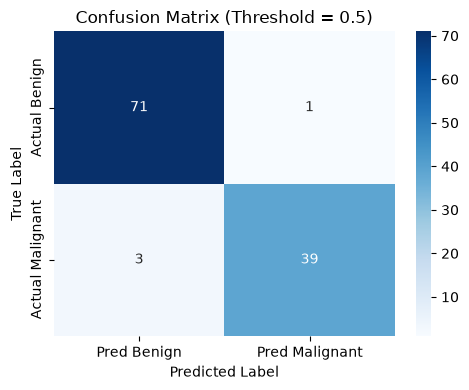


Top 5 features associated with MALIGNANCY:
            feature  coefficient
      texture_worst     1.434093
          radius_se     1.233325
     symmetry_worst     1.061264
concave points_mean     0.952813
    concavity_worst     0.911406

Top 5 features associated with BENIGN diagnosis:
             feature  coefficient
         symmetry_se    -0.330658
          texture_se    -0.407611
    compactness_mean    -0.439546
fractal_dimension_se    -0.593876
      compactness_se    -0.906925

--- Decision Threshold Analysis ---
Threshold  Precision   Recall     F1-Score  
------------------------------------------
0.1        0.891       0.976      0.932     
0.2        0.911       0.976      0.943     
0.3        0.976       0.976      0.976     
0.4        0.976       0.952      0.964     
0.5        0.975       0.929      0.951     
0.6        1.000       0.905      0.950     
0.7        1.000       0.905      0.950     
0.8        1.000       0.857      0.923     
0.9        1.000   

In [2]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# 1. LOAD & PREPROCESS DATA

df = pd.read_csv("/Users/spoorthin/Downloads/data.csv")

# Drop unnecessary identifier and trailing empty column if present
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Encode target: Malignant (M) = 1 (Positive), Benign (B) = 0 (Negative)
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

print("Dataset Shape:", df.shape)
print("\nClass Distribution:\n", df["diagnosis"].value_counts())
print("\nTotal Missing Values:", df.isnull().sum().sum())

# 2. TRAIN-TEST SPLIT

X = df.drop(columns="diagnosis")
y = df["diagnosis"]

# Stratified split preserves the benign-to-malignant ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


# 3. PIPELINE SETUP & MODEL TRAINING

# Scaling inside the pipeline prevents data leakage from the test set
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)

# 4. PREDICTIONS & EVALUATION (Default Threshold = 0.5)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("\n--- Model Evaluation (Threshold = 0.5) ---")
print(f"Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob):.4f}")

print("\nFull Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))

# Confusion matrix visualization
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Benign", "Pred Malignant"],
    yticklabels=["Actual Benign", "Actual Malignant"]
)
plt.title("Confusion Matrix (Threshold = 0.5)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# 5. FEATURE IMPORTANCE (Standardized Coefficients)

coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.named_steps["logreg"].coef_[0]
}).sort_values("coefficient", ascending=False)

print("\nTop 5 features associated with MALIGNANCY:")
print(coef_df.head(5).to_string(index=False))

print("\nTop 5 features associated with BENIGN diagnosis:")
print(coef_df.tail(5).to_string(index=False))

# 6. THRESHOLD TUNING (Precision vs. Recall Trade-off)
print("\n--- Decision Threshold Analysis ---")
print(f"{'Threshold':<10} {'Precision':<11} {'Recall':<10} {'F1-Score':<10}")
print("-" * 42)

for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred_t = (y_prob >= t).astype(int)
    p = precision_score(y_test, pred_t, zero_division=0)
    r = recall_score(y_test, pred_t)
    f1 = f1_score(y_test, pred_t)
    print(f"{t:<10.1f} {p:<11.3f} {r:<10.3f} {f1:<10.3f}")

